In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("bank-additional-full.csv", sep=";")

print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum().sum())

display(df.head())

Dataset shape: (41188, 21)

Missing values:
0


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [2]:
outcome_counts = df["y"].value_counts()

print("Campaign outcomes:")
print(outcome_counts)

total_contacts = len(df)
conversions = (df["y"] == "yes").sum()
non_conversions = (df["y"] == "no").sum()

conversion_rate = (conversions / total_contacts) * 100

print("\nTotal contacts:", total_contacts)
print("Successful conversions:", conversions)
print("Non-conversions:", non_conversions)
print(f"Overall conversion rate: {conversion_rate:.2f}%")


Campaign outcomes:
y
no     36548
yes     4640
Name: count, dtype: int64

Total contacts: 41188
Successful conversions: 4640
Non-conversions: 36548
Overall conversion rate: 11.27%


In [3]:
contact_analysis = df.groupby("contact").agg(
    Total_Contacts=("y", "count"),
    Conversions=("y", lambda x: (x == "yes").sum())
)

contact_analysis["Conversion_Rate_%"] = (
    contact_analysis["Conversions"] /
    contact_analysis["Total_Contacts"] * 100
).round(2)

print(contact_analysis.sort_values(
    "Conversion_Rate_%", ascending=False
))


           Total_Contacts  Conversions  Conversion_Rate_%
contact                                                  
cellular            26144         3853              14.74
telephone           15044          787               5.23


In [4]:
month_analysis = df.groupby("month").agg(
    Total_Contacts=("y", "count"),
    Conversions=("y", lambda x: (x == "yes").sum())
)

month_analysis["Conversion_Rate_%"] = (
    month_analysis["Conversions"] /
    month_analysis["Total_Contacts"] * 100
).round(2)

print(
    month_analysis.sort_values(
        "Conversion_Rate_%", ascending=False
    )
)


       Total_Contacts  Conversions  Conversion_Rate_%
month                                                
mar               546          276              50.55
dec               182           89              48.90
sep               570          256              44.91
oct               718          315              43.87
apr              2632          539              20.48
aug              6178          655              10.60
jun              5318          559              10.51
nov              4101          416              10.14
jul              7174          649               9.05
may             13769          886               6.43


In [5]:
previous_analysis = df.groupby("poutcome").agg(
    Total_Contacts=("y", "count"),
    Conversions=("y", lambda x: (x == "yes").sum())
)

previous_analysis["Conversion_Rate_%"] = (
    previous_analysis["Conversions"] /
    previous_analysis["Total_Contacts"] * 100
).round(2)

print(
    previous_analysis.sort_values(
        "Conversion_Rate_%", ascending=False
    )
)


             Total_Contacts  Conversions  Conversion_Rate_%
poutcome                                                   
success                1373          894              65.11
failure                4252          605              14.23
nonexistent           35563         3141               8.83


In [6]:
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=["18–25", "26–35", "36–45", "46–55", "56–65", "65+"]
)

age_analysis = df.groupby("age_group", observed=False).agg(
    Total_Contacts=("y", "count"),
    Conversions=("y", lambda x: (x == "yes").sum())
)

age_analysis["Conversion_Rate_%"] = (
    age_analysis["Conversions"] /
    age_analysis["Total_Contacts"] * 100
).round(2)

print(age_analysis)

           Total_Contacts  Conversions  Conversion_Rate_%
age_group                                                
18–25                1666          349              20.95
26–35               14847         1740              11.72
36–45               12844         1093               8.51
46–55                8249          717               8.69
56–65                2963          451              15.22
65+                   619          290              46.85


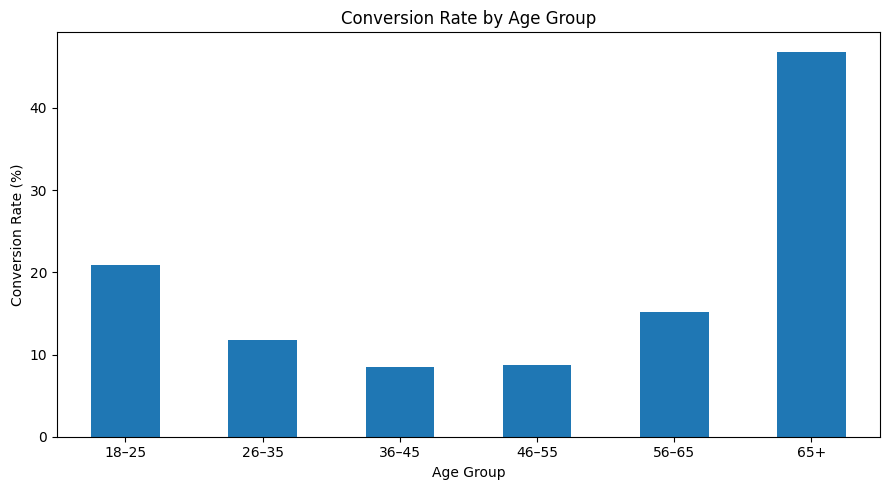

In [7]:
age_analysis["Conversion_Rate_%"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Conversion Rate by Age Group",
    ylabel="Conversion Rate (%)",
    xlabel="Age Group",
    rot=0
)

plt.tight_layout()
plt.show()

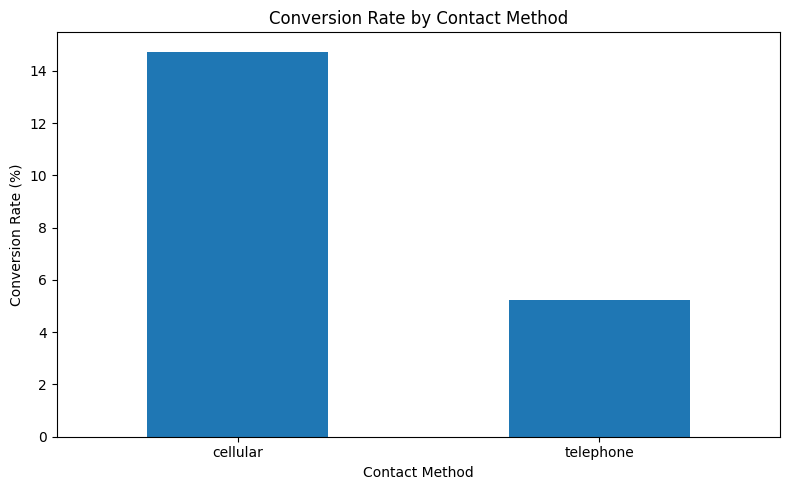

In [8]:
contact_analysis["Conversion_Rate_%"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Conversion Rate by Contact Method",
    ylabel="Conversion Rate (%)",
    xlabel="Contact Method",
    rot=0
)

plt.tight_layout()
plt.show()

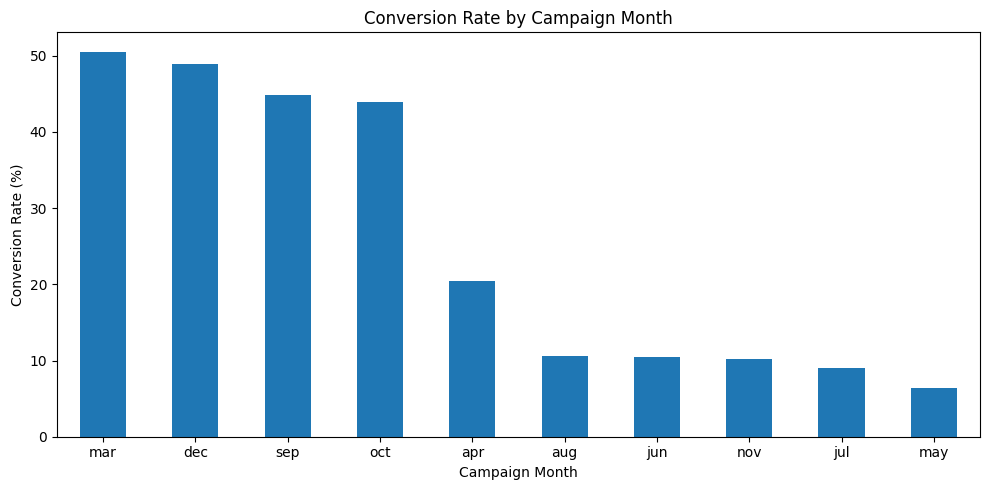

In [9]:
month_analysis["Conversion_Rate_%"].sort_values(ascending=False).plot(
    kind="bar",
    figsize=(10, 5),
    title="Conversion Rate by Campaign Month",
    ylabel="Conversion Rate (%)",
    xlabel="Campaign Month",
    rot=0
)

plt.tight_layout()
plt.show()

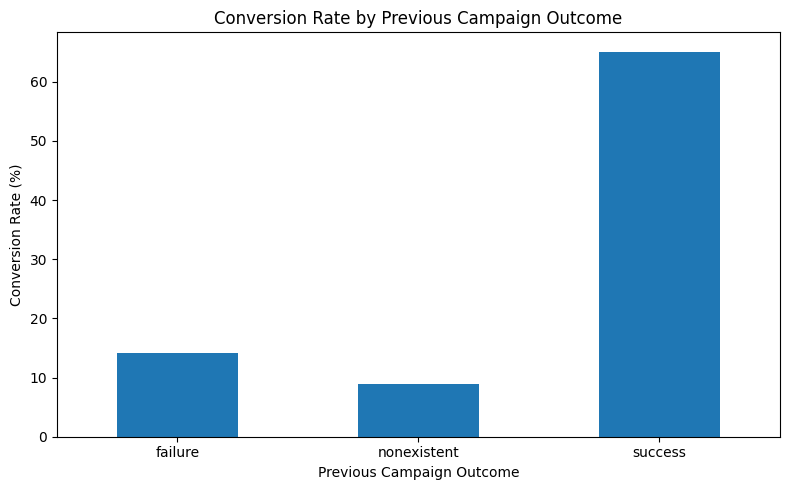

In [10]:
previous_analysis["Conversion_Rate_%"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Conversion Rate by Previous Campaign Outcome",
    ylabel="Conversion Rate (%)",
    xlabel="Previous Campaign Outcome",
    rot=0
)

plt.tight_layout()
plt.show()

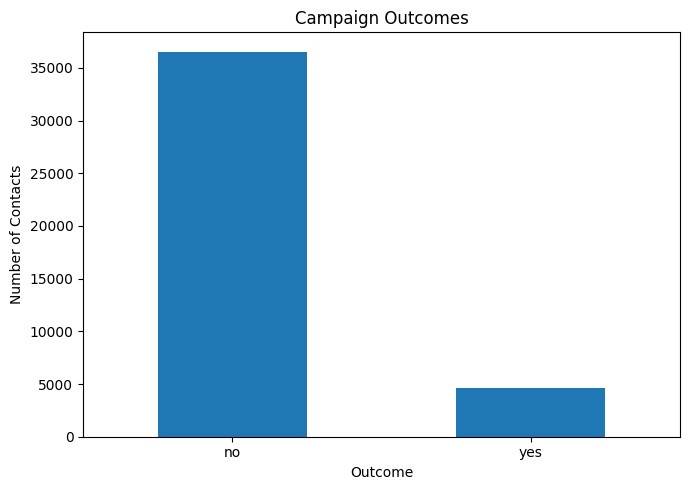

In [11]:
outcome_counts.plot(
    kind="bar",
    figsize=(7, 5),
    title="Campaign Outcomes",
    ylabel="Number of Contacts",
    xlabel="Outcome",
    rot=0
)

plt.tight_layout()
plt.show()

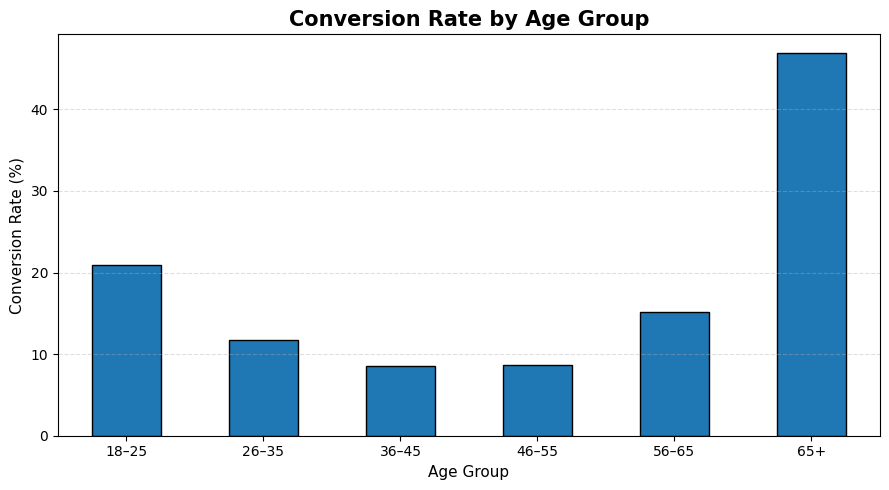

In [12]:
plt.figure(figsize=(9, 5))

age_analysis["Conversion_Rate_%"].plot(
    kind="bar",
    rot=0,
    edgecolor="black"
)

plt.title("Conversion Rate by Age Group", fontsize=15, fontweight="bold")
plt.xlabel("Age Group", fontsize=11)
plt.ylabel("Conversion Rate (%)", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

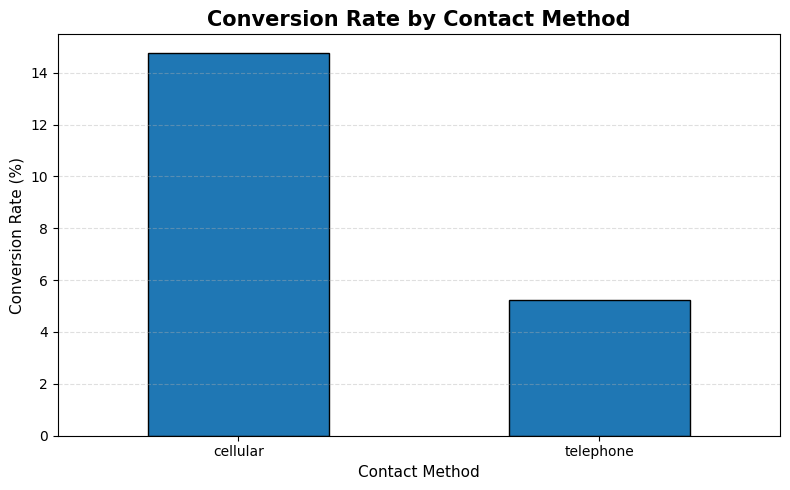

In [13]:
plt.figure(figsize=(8, 5))

contact_analysis["Conversion_Rate_%"].plot(
    kind="bar",
    rot=0,
    edgecolor="black"
)

plt.title("Conversion Rate by Contact Method",
          fontsize=15, fontweight="bold")
plt.xlabel("Contact Method", fontsize=11)
plt.ylabel("Conversion Rate (%)", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

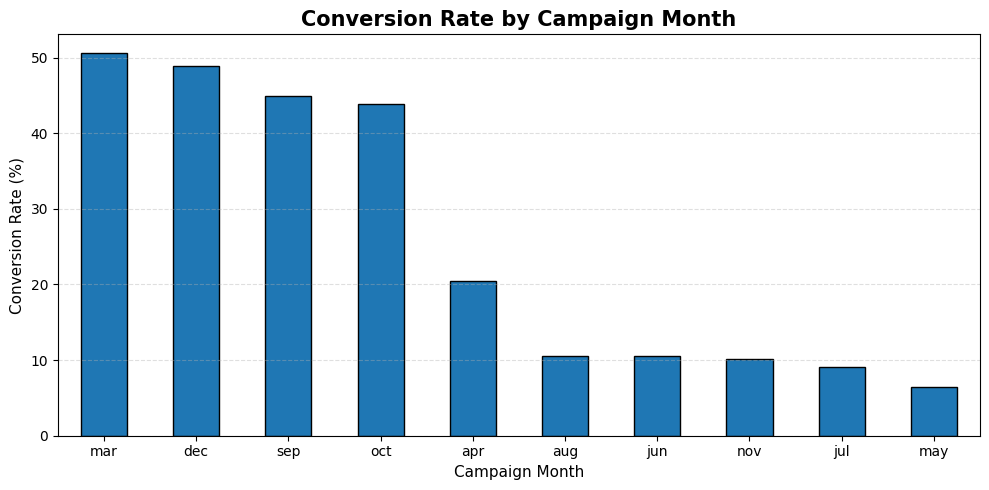

In [15]:
plt.figure(figsize=(10, 5))

month_analysis["Conversion_Rate_%"].sort_values(ascending=False).plot(
    kind="bar",
    rot=0,
    edgecolor="black"
)

plt.title("Conversion Rate by Campaign Month",
          fontsize=15, fontweight="bold")
plt.xlabel("Campaign Month", fontsize=11)
plt.ylabel("Conversion Rate (%)", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

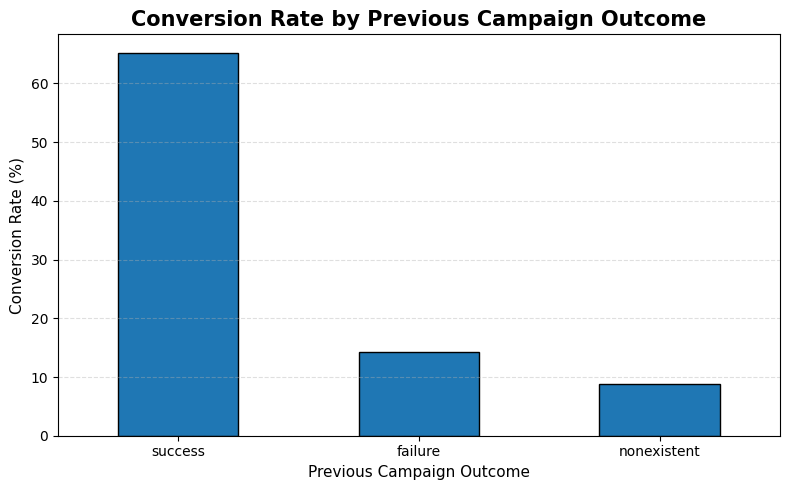

In [16]:
plt.figure(figsize=(8, 5))

previous_analysis["Conversion_Rate_%"].sort_values(
    ascending=False
).plot(
    kind="bar",
    rot=0,
    edgecolor="black"
)

plt.title(
    "Conversion Rate by Previous Campaign Outcome",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Previous Campaign Outcome", fontsize=11)
plt.ylabel("Conversion Rate (%)", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

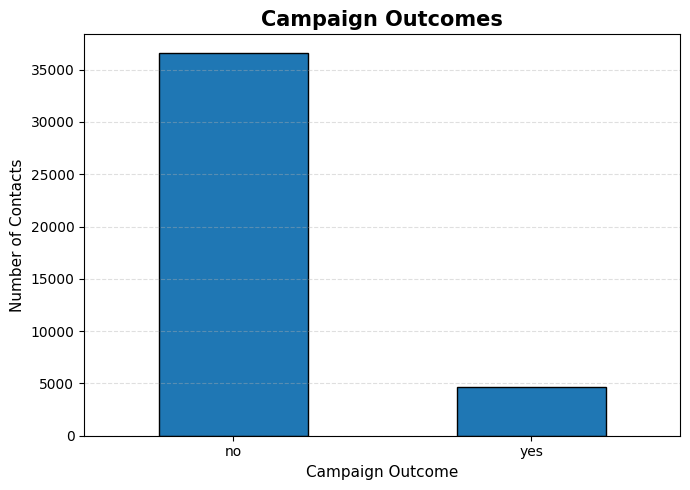

In [17]:
plt.figure(figsize=(7, 5))

outcome_counts.plot(
    kind="bar",
    rot=0,
    edgecolor="black"
)

plt.title("Campaign Outcomes", fontsize=15, fontweight="bold")
plt.xlabel("Campaign Outcome", fontsize=11)
plt.ylabel("Number of Contacts", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()